In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv(r'C:\Users\ASUS\OneDrive\Desktop\ICT DSA\Assignment\Clustering\Wine_clust.csv')

In [6]:
data.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [8]:
data.shape

(178, 13)

In [9]:
data.isna().sum()

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

In [10]:
data.shape

(178, 13)

In [11]:
data.dtypes

Alcohol                 float64
Malic_Acid              float64
Ash                     float64
Ash_Alcanity            float64
Magnesium                 int64
Total_Phenols           float64
Flavanoids              float64
Nonflavanoid_Phenols    float64
Proanthocyanins         float64
Color_Intensity         float64
Hue                     float64
OD280                   float64
Proline                   int64
dtype: object

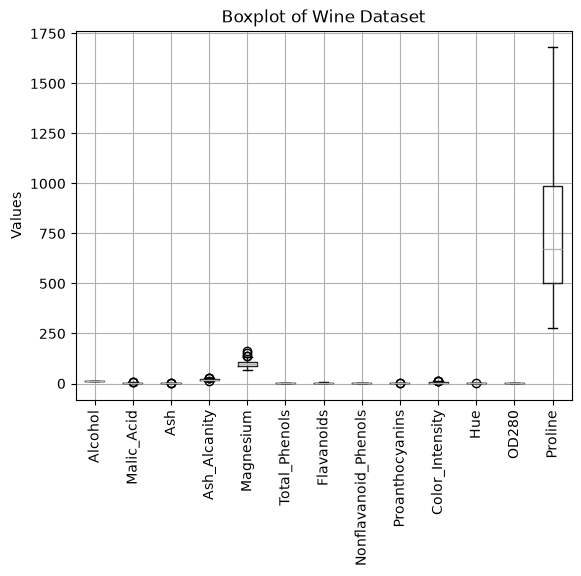

In [12]:
data.boxplot()

plt.xticks(rotation=90)
plt.title("Boxplot of Wine Dataset")
plt.ylabel("Values")
plt.show()

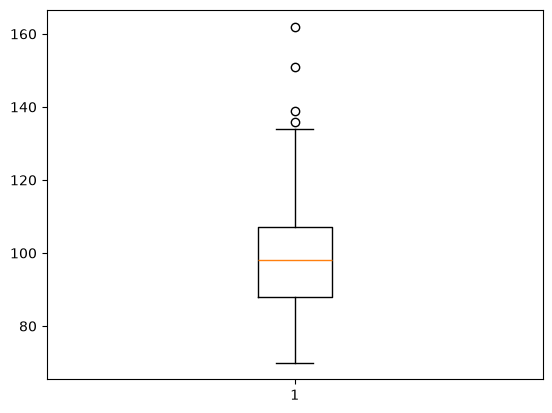

In [13]:
plt.boxplot(data['Magnesium'])
plt.show()

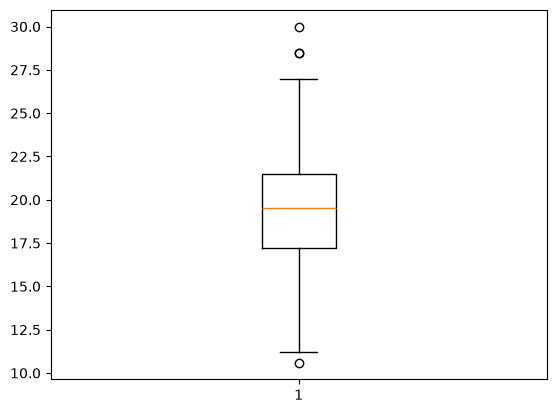

In [14]:
plt.boxplot(data['Ash_Alcanity'])
plt.show()

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [16]:
data_scaled = scaler.fit_transform(data)

data_scaled = pd.DataFrame(
    data_scaled,
    columns=data.columns
)

K Means

In [17]:
from sklearn.cluster import KMeans

In [18]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [19]:
wcss = []
for i in range(2,10):
    k_means = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    k_means.fit(data_scaled)
    wcss.append(k_means.inertia_)

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows wi

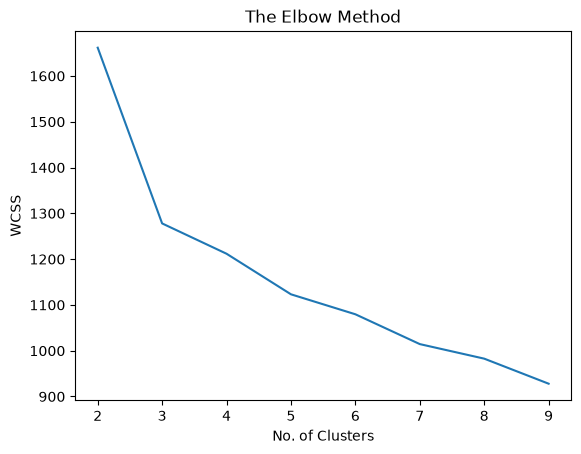

In [20]:
plt.plot(range(2,10),wcss)
plt.title('The Elbow Method')
plt.xlabel('No. of Clusters')
plt.ylabel('WCSS')
plt.show()

In [21]:
k_means = KMeans(n_clusters = 5, init = 'k-means++', random_state = 42)
y_kmeans = k_means.fit_predict(data)

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [22]:
 from sklearn.metrics import silhouette_score

In [23]:
sil_scores = []
for i in range(2,10):
    k_means = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    y_kmeans = k_means.fit_predict(data_scaled)
    s_score = silhouette_score(data_scaled,y_kmeans)
    sil_scores.append(s_score)

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows wi

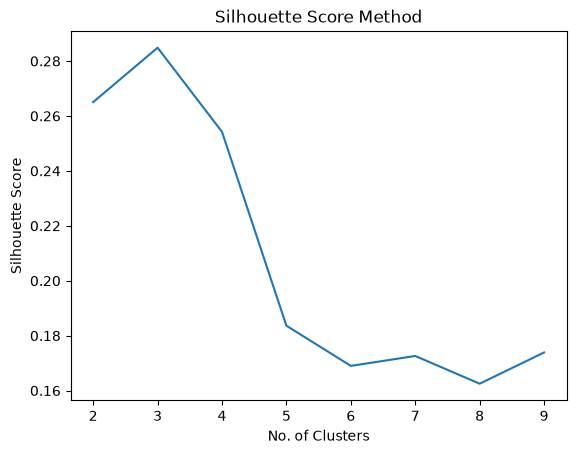

In [24]:
plt.plot(range(2,10),sil_scores)
plt.title('Silhouette Score Method')
plt.xlabel('No. of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

In [25]:
optimal_k_kmeans = range(2, 10)[np.argmax(sil_scores)]
best_kmeans_score = max(sil_scores)

print("Optimal number of clusters:", optimal_k_kmeans)
print("Best Silhouette Score:", round(best_kmeans_score, 4))

Optimal number of clusters: 3
Best Silhouette Score: 0.2849


AHC

In [26]:
from sklearn.cluster import AgglomerativeClustering

In [27]:
sil_scores_ahc = []
for i in range(2,10):
    ahc = AgglomerativeClustering(n_clusters = i,linkage = 'ward')
    y_ahc = ahc.fit_predict(data_scaled)
    s_score_ahc = silhouette_score(data_scaled, y_ahc)
    sil_scores_ahc.append(s_score_ahc)

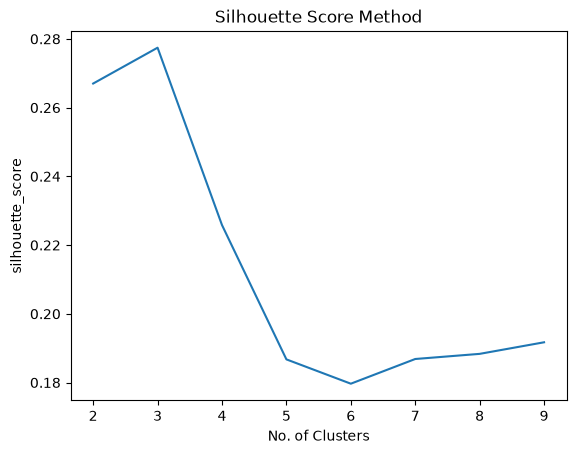

In [28]:
plt.plot(range(2,10),sil_scores_ahc)
plt.title('Silhouette Score Method')
plt.xlabel('No. of Clusters')
plt.ylabel('silhouette_score')
plt.show()

In [29]:
import scipy.cluster.hierarchy as sch

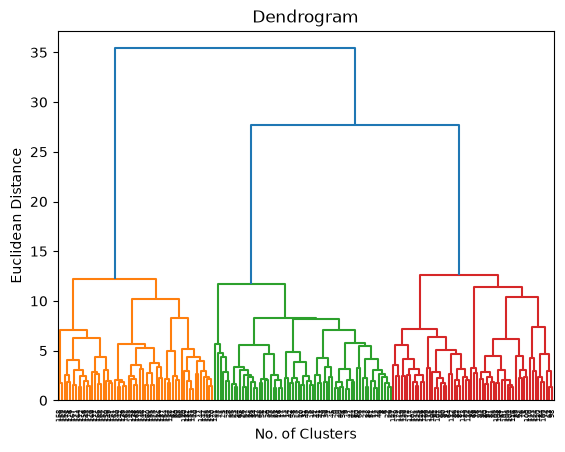

In [30]:
dendrogram = sch.dendrogram(sch.linkage(data_scaled, method = 'ward'))
plt.title('Dendrogram')
plt.xlabel('No. of Clusters')
plt.ylabel('Euclidean Distance')
plt.show()

In [31]:
Z = sch.linkage(data, method='ward')

distances = Z[:, 2]

acceleration = np.diff(distances, 2)

idx = np.argmax(acceleration)

n_samples = data.shape[0]
optimal_k = n_samples- (idx + 2)
print("Suggested number of clusters:", optimal_k)

Suggested number of clusters: 2


In [32]:
optimal_k_ahc = range(2, 10)[np.argmax(sil_scores_ahc)]

print("Optimal number of clusters for AHC:", optimal_k_ahc)

Optimal number of clusters for AHC: 3


In [33]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)

In [34]:
ahc_score = silhouette_score(data_scaled, y_ahc)

print("AHC Silhouette Score:", round(ahc_score, 4))

AHC Silhouette Score: 0.1917


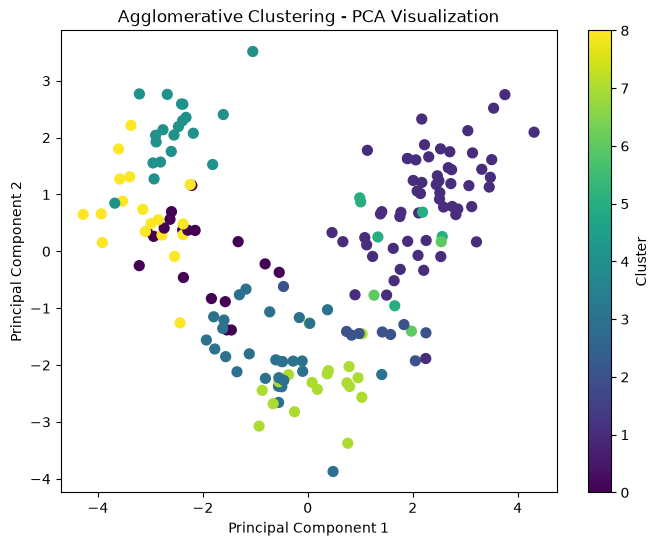

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(
    data_pca[:, 0],
    data_pca[:, 1],
    c = y_ahc,
    cmap = 'viridis',
    s = 50
)

plt.title("Agglomerative Clustering - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [36]:
kmeans_score = silhouette_score(data_scaled, y_kmeans)

print("K-Means Silhouette Score:", round(kmeans_score, 4))

K-Means Silhouette Score: 0.1739


In [37]:
comparison = pd.DataFrame({
    "Model": ["K-Means", "AHC"],
    
    "Optimal Number of Clusters": [
        optimal_k_kmeans,
        range(2, 10)[np.argmax(sil_scores_ahc)]
    ],
    
    "Silhouette Score": [
        kmeans_score,
        ahc_score
    ]
})

comparison["Silhouette Score"] = comparison["Silhouette Score"].round(4)

In [38]:
comparison

,Model,Optimal Number of Clusters,Silhouette Score
0,K-Means,3,0.1739
1,AHC,3,0.1917


In [39]:
best_model = comparison.loc[comparison["Silhouette Score"].idxmax()]

print("Best Clustering Model:", best_model["Model"])
print("Optimal Number of Clusters:", int(best_model["Optimal Number of Clusters"]))
print("Silhouette Score:", best_model["Silhouette Score"])

Best Clustering Model: AHC
Optimal Number of Clusters: 3
Silhouette Score: 0.1917


In [40]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

data_pca = pca.fit_transform(data_scaled)

print("Original number of features:", data_scaled.shape[1])
print("Reduced number of features:", data_pca.shape[1])

Original number of features: 13
Reduced number of features: 2
